## Ćwiczenie 9-0: Wprowadzenie do Analizy Widmowej Obrazów (2D FFT)
**Cel:** Zrozumienie podstaw dwuwymiarowej Transformaty Fouriera (2D FFT) w kontekście cyfrowego przetwarzania obrazów medycznych.

#### 1. Częstotliwość w Dziedzinie Przestrzennej
W klasycznej analizie sygnałów (np. dźwięku) częstotliwość oznacza liczbę drgań w czasie. W przypadku **obrazów (sygnałów dwuwymiarowych)** mówimy o **częstotliwości przestrzennej**.

* Oznacza ona, jak szybko zmienia się jasność pikseli wzdłuż osi X i Y.
* **Niskie częstotliwości:** Obszary, gdzie jasność zmienia się powoli (np. jednolite tło, gładka tkanka, duże kształty narządów).
* **Wysokie częstotliwości:** Obszary, gdzie jasność zmienia się bardzo gwałtownie (np. ostre krawędzie kości, drobne detale, szum matrycy).

#### 2. Dwuwymiarowa Transformata Fouriera (2D FFT)
Transformata Fouriera pozwala na przejście z **dziedziny przestrzennej** (piksele) do **dziedziny częstotliwości** (fale). Zgodnie z tw. Fouriera, każdy obraz można rozłożyć na sumę dwuwymiarowych fal sinusoidalnych o różnych częstotliwościach, amplitudach i kierunkach.

Wynikiem operacji 2D FFT na obrazie jest macierz liczb zespolonych. Z każdej takiej liczby (komponenty częstotliwościowej) możemy wyciągnąć dwie kluczowe informacje:
1. **Widmo Amplitudowe (Amplituda):** Mówi nam, *ile* danej fali znajduje się w obrazie. To ją najczęściej wizualizujemy podczas zajęć, ponieważ informuje nas o występowaniu zakłóceń.
2. **Widmo Fazowe (Faza):** Mówi nam, *gdzie* dana fala jest umiejscowiona w przestrzeni. Choć wizualnie wygląda jak szum, to właśnie faza przechowuje kluczowe informacje o strukturze i położeniu wszystkich krawędzi.

#### 3. Poprawna Wizualizacja Widma Amplitudowego
Gdy wyliczymy FFT dla obrazu (np. w Pythonie używając `np.fft.fft2`), bezpośrednie wyświetlenie wyniku jako obrazu jest nieczytelne. Aby przeprowadzić sensowną analizę inżynierską, musimy wykonać dwa kroki:

* **Przesunięcie (fftshift):** Algorytmy FFT domyślnie umieszczają zerowe (najniższe) częstotliwości w rogach macierzy. Używamy funkcji przesuwającej, aby przenieść je na sam środek obrazu. Dzięki temu **środek widma to składowa stała i niskie częstotliwości**, a im dalej od środka ku krawędziom, tym częstotliwości są wyższe.
* **Skala logarytmiczna:** Różnica między ogromną energią składowej stałej (średnią jasnością obrazu w centrum) a małą energią drobnego szumu na krawędziach jest gigantyczna. Dlatego widmo amplitudowe wyświetla się z nałożoną skalą logarytmiczną: `log(1 + abs(widmo))`. Bez tego zobaczylibyśmy tylko jeden biały piksel na środku czarnego ekranu.

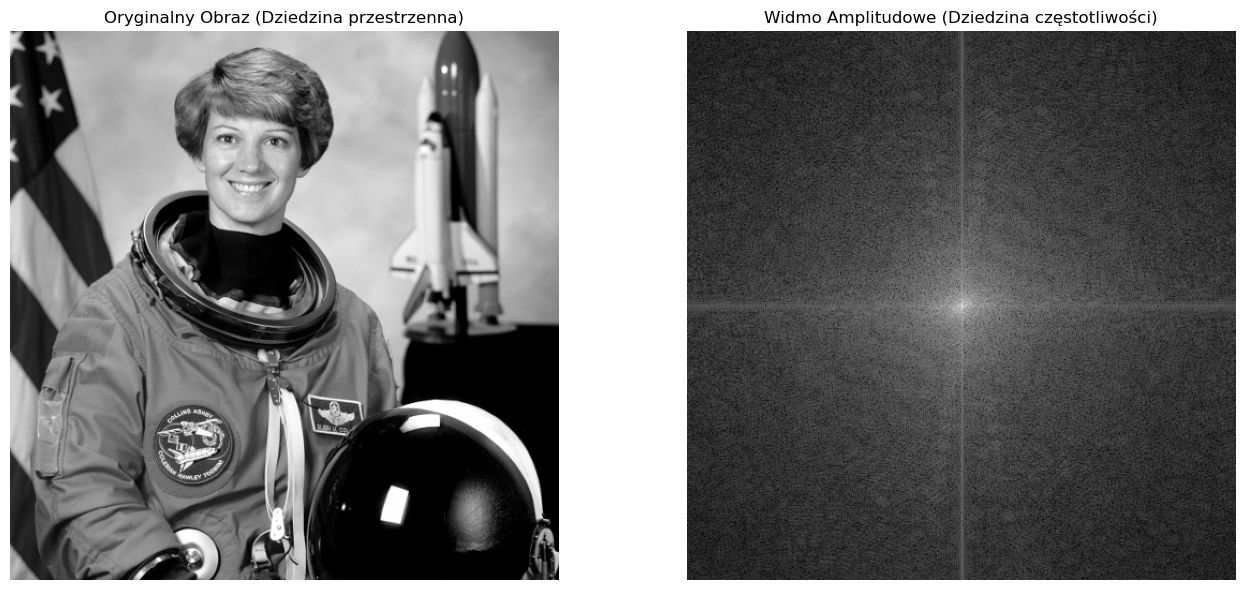

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, io, color

image = data.astronaut()
image_gray = color.rgb2gray(image)

# 1. Wyliczenie Dwuwymiarowej Transformaty Fouriera
fft_result = np.fft.fft2(image_gray)

# 2. Przesunięcie zerowych częstotliwości (składowej stałej) na środek macierzy
fft_shifted = np.fft.fftshift(fft_result)

# 3. Wyciągnięcie modułu z liczb zespolonych (amplitudy) i nałożenie skali logarytmicznej
#    Dodajemy 1, aby uniknąć operacji log(0) dla idealnie czarnych miejsc w widmie
magnitude_spectrum = np.log(1 + np.abs(fft_shifted))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Wyświetlanie oryginalnego obrazu
axes[0].imshow(image_gray, cmap='gray')
axes[0].set_title('Oryginalny Obraz (Dziedzina przestrzenna)')
axes[0].axis('off')

# Wyświetlanie widma amplitudowego
axes[1].imshow(magnitude_spectrum, cmap='gray')
axes[1].set_title('Widmo Amplitudowe (Dziedzina częstotliwości)')
axes[1].axis('off')

# Zmniejszenie odstępów między wykresami
plt.tight_layout()
plt.show()

#### 4. Znaczenie poszczególnych rejonów w widmie (Mapa Nawigacyjna)
Analizując wycentrowane widmo amplitudowe, możemy łatwo zidentyfikować kluczowe komponenty oryginalnego zdjęcia medycznego:
* **Centrum (jasny punkt):** Składowa stała (DC) – średnia jasność całego obrazu oraz otaczające ją niskie częstotliwości (tworzące rozmyte zarysy tkanek).
* **Dalekie peryferia:** Szum pomiarowy i bardzo ostre, drobne przejścia tonalne.
* **Krzyż na osiach głównych:** Częstotliwości układające się idealnie w poziomie lub pionie, często wynikające z ram obrazu lub silnych pionowych/poziomych struktur.
* **Lokalne jasne punkty (piki) oddalone od centrum:** Reprezentują silny, okresowy wzorzec na obrazie (np. powtarzające się prążki, siatki, artefakty z rezonansu lub aparatury USG). 

#### 5. Zasady Filtracji w Dziedzinie Częstotliwości
Głównym powodem, dla którego przechodzimy do dziedziny Fouriera, jest możliwość łatwego manipulowania cechami obrazu poprzez prostą operację **mnożenia** (w dziedzinie przestrzennej wymuszałoby to operacje splotu).

Tworzymy **Maskę Filtru** (fizyczną macierz złożoną z zer i jedynek o rozmiarach widma) i mnożymy ją przez nasze widmo:
1. **Filtr Dolnoprzepustowy (Low-pass filter):** Maska ma jedynki na środku, zera na brzegach. Przepuszcza niskie częstotliwości, fizycznie ucina i zeruje wysokie. 
   * **Efekt na obrazie po odwróceniu (IFFT):** Mocne rozmycie, utrata ostrych krawędzi, skuteczne usunięcie szumu (matematyczny odpowiednik filtru Gaussa).
2. **Filtr Górnoprzepustowy (High-pass filter):** Zera na środku, jedynki na brzegach. Ucina tło i duże gradienty, pozostawia fale o wysokiej częstotliwości.
   * **Efekt na obrazie po odwróceniu (IFFT):** Wyostrzenie, usunięcie tła, idealna detekcja konturów i krawędzi tkanek.
3. **Filtr Zaporowy (Notch filter):** Specjalistyczny filtr inżynierski. Składa się z samych jedynek, ale ma wycięte zera punktowo – tylko w miejscach odpowiadających jasnym pikom zakłóceń sprzętowych.
   * **Efekt na obrazie po odwróceniu (IFFT):** Chirurgiczne usunięcie regularnych pasów i artefaktów pomiarowych, przy pełnym zachowaniu naturalnej ostrości reszty obrazu medycznego.

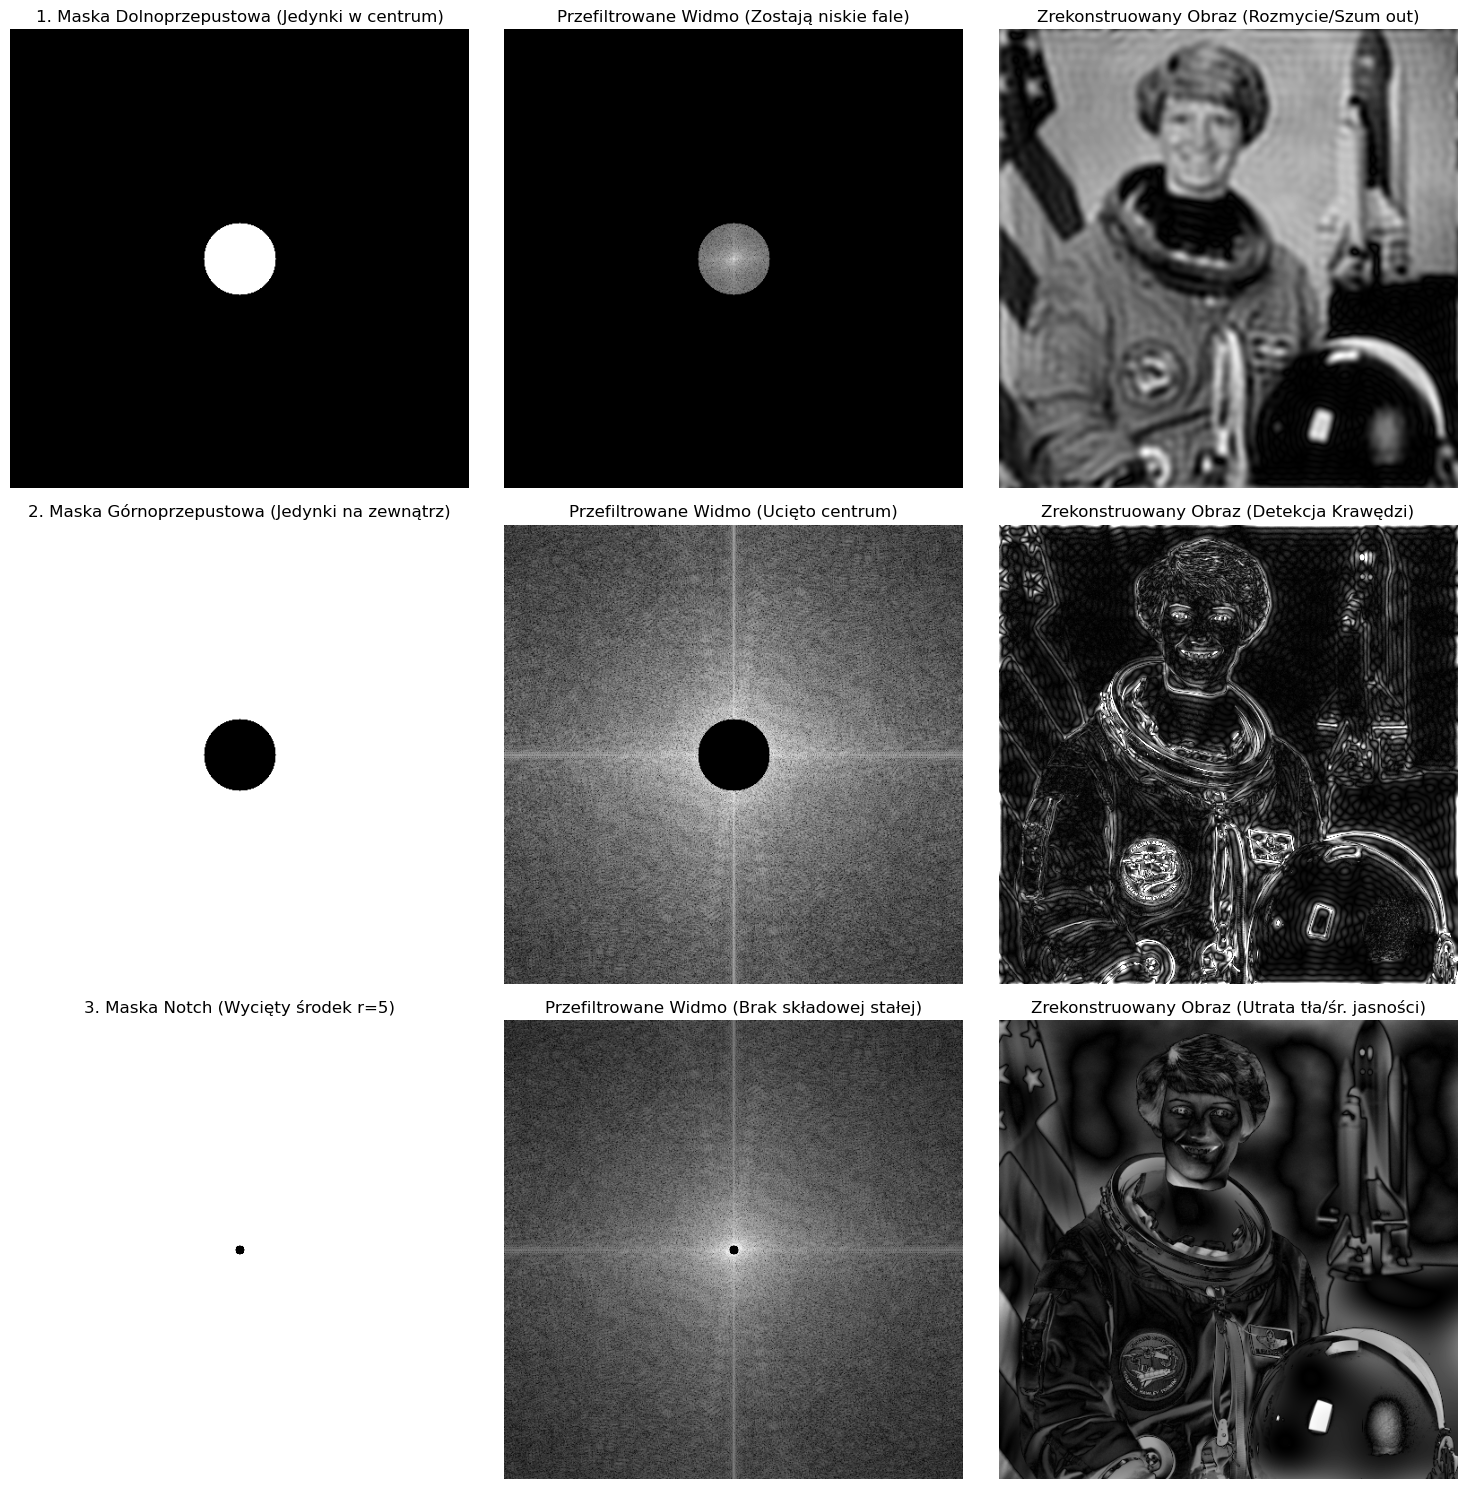

In [21]:
rows, cols = image_gray.shape
center_row, center_col = rows // 2, cols // 2

# Wygenerowanie siatki współrzędnych X,Y by łatwo tworzyć koła na środku
Y, X = np.ogrid[:rows, :cols]
distance_from_center = np.sqrt((X - center_col)**2 + (Y - center_row)**2)

# Promień odcięcia (w pikselach od centrum)
cutoff_radius = 40


# =========================================================
# FILTR 1: DOLNOPRZEPUSTOWY (Low-Pass Filter)
# =========================================================
# Maska: 1 w promieniu cutoff_radius, zera na zewnątrz
lpf_mask = distance_from_center <= cutoff_radius

# Filtracja (wymnożenie widma) i Rekonstrukcja IFFT
filtered_fft_lpf = fft_shifted * lpf_mask
img_lpf_reconstructed = np.abs(np.fft.ifft2(np.fft.ifftshift(filtered_fft_lpf)))


# =========================================================
# FILTR 2: GÓRNOPRZEPUSTOWY (High-Pass Filter)
# =========================================================
# Maska: Zera w promieniu cutoff_radius, 1 na zewnątrz 
# (Odwrócenie filtru LPF)
hpf_mask = ~lpf_mask 

# Filtracja i Rekonstrukcja IFFT
filtered_fft_hpf = fft_shifted * hpf_mask
img_hpf_reconstructed = np.abs(np.fft.ifft2(np.fft.ifftshift(filtered_fft_hpf)))


# =========================================================
# FILTR 3: ZAPOROWY (Notch Filter) - Odrzucenie stałej (DC)
# =========================================================
# Maska: Zera tylko w bardzo małym kółku (r=5) idealnie na środku
notch_mask = distance_from_center > 5

# Filtracja i Rekonstrukcja IFFT
filtered_fft_notch = fft_shifted * notch_mask
img_notch_reconstructed = np.abs(np.fft.ifft2(np.fft.ifftshift(filtered_fft_notch)))


# =========================================================
# WIZUALIZACJA: Porównanie 3 metod filtracji
# =========================================================
fig, axes = plt.subplots(3, 3, figsize=(15, 15))

# --- Rząd 1: Dolnoprzepustowy (Low-Pass) ---
axes[0, 0].imshow(lpf_mask, cmap='gray')
axes[0, 0].set_title('1. Maska Dolnoprzepustowa (Jedynki w centrum)')
axes[0, 1].imshow(np.log(1 + np.abs(filtered_fft_lpf)), cmap='gray')
axes[0, 1].set_title('Przefiltrowane Widmo (Zostają niskie fale)')
axes[0, 2].imshow(img_lpf_reconstructed, cmap='gray')
axes[0, 2].set_title('Zrekonstruowany Obraz (Rozmycie/Szum out)')

# --- Rząd 2: Górnoprzepustowy (High-Pass) ---
axes[1, 0].imshow(hpf_mask, cmap='gray')
axes[1, 0].set_title('2. Maska Górnoprzepustowa (Jedynki na zewnątrz)')
axes[1, 1].imshow(np.log(1 + np.abs(filtered_fft_hpf)), cmap='gray')
axes[1, 1].set_title('Przefiltrowane Widmo (Ucięto centrum)')
# Wysokie częstotliwości (krawędzie) mają małe amplitudy w dziedzinie pikseli,
# używamy parametru 'vmax' by odpowiednio to wyświetlić (kontrast krawędzi)
axes[1, 2].imshow(img_hpf_reconstructed, cmap='gray', vmax=np.percentile(img_hpf_reconstructed, 99))
axes[1, 2].set_title('Zrekonstruowany Obraz (Detekcja Krawędzi)')

# --- Rząd 3: Zaporowy (Notch) usuwający środek ---
axes[2, 0].imshow(notch_mask, cmap='gray')
axes[2, 0].set_title('3. Maska Notch (Wycięty środek r=5)')
axes[2, 1].imshow(np.log(1 + np.abs(filtered_fft_notch)), cmap='gray')
axes[2, 1].set_title('Przefiltrowane Widmo (Brak składowej stałej)')
axes[2, 2].imshow(img_notch_reconstructed, cmap='gray')
axes[2, 2].set_title('Zrekonstruowany Obraz (Utrata tła/śr. jasności)')

for ax in axes.flat:
    ax.axis('off')

plt.tight_layout()
plt.show()